# Project — Home energy diagnoses — *DPE logements existants (depuis juillet 2021)*
**MSA-DATI07-03 · Advanced EDA & Data Collection** · difficulty ⭐⭐⭐ hard

This is your **project notebook**. It already follows the six-section structure from Session 6 and contains working collection code for this API. Your job: fill every `# TODO` and every *TODO* markdown cell, on **real data you collected yourselves**.

| # | Section | Answers the question… |
|---|---|---|
| 1 | Context & provenance | Where does this data come from, and what question is it for? |
| 2 | Setup & parameters | Can someone else run this and get the same thing? |
| 3 | Collection, ingestion & schema | Did we collect it properly, and is it what we think it is? |
| 4 | Data quality | What is missing, duplicated or weird — and what did we decide? |
| 5 | Exploration | What does the data say? Every figure captioned. |
| 6 | Findings & next steps | What can a modeller trust, and what should they test? |

**Deliverables:** this notebook (Restart & Run All passes, same fingerprint twice) · `requirements.txt` · the 2-page data-quality report (`DATA_QUALITY_REPORT_TEMPLATE.md`) · regular Git commits.

**Possible questions** (pick one or write your own — one per group):
- How are energy labels (A–G) distributed, and how do they relate to construction period and surface?
- Which dwellings are 'passoires thermiques' (F/G), and where are they?
- How consistent are the diagnoses: same dwelling diagnosed twice with different results?

---
## 1 · Context & provenance

*This card records the project scope before the analysis. The collection date and unit of observation will be confirmed after the API collection cell has run successfully.*

| Field | Your answer |
|---|---|
| **Business question** | Among DPE diagnosis records, how are energy labels distributed, and how are they associated with construction period and dwelling surface? |
| **Source** | ADEME open-data portal (data.ademe.fr), Data Fair API, dataset `dpe03existant` |
| **Dataset page / API docs** | https://data.ademe.fr/datasets/dpe03existant |
| **Collected by / when** | Group 6. Novemeber 6, 2026
| **Collection method** | REST API, paginated, cached with `requests-cache`, with retries for temporary API errors and a pause between non-cached requests |
| **Filters applied** | `code_departement_ban:"75"`; the API request uses a page size of 1,000 records and the notebook collection is capped at `MAX_ROWS = 10_000` |
| **Licence / constraints** | Licence Ouverte / Etalab 2.0, subject to confirmation on the ADEME dataset page |
| **Unit of observation** | One row represents one DPE energy-diagnosis record. |
| **Known limitations** | The collection is filtered to department 75 and capped at 10,000 rows, so it is not a complete extract of the national dataset. The API is a snapshot that may change between collection runs. Several records may share an address because they can represent different dwellings or successive diagnoses. Some variables may contain missing, undocumented or structurally non-applicable values. The analysis will describe associations, not prove causal relationships. |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session.

In [1]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [2]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "data"
REPORT_DIR = "reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week
IQR_K = 1.5
MAX_MISSING_SHARE = 0.30

BASE_URL = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe03existant/lines"
QUERY = {"size": 1000,
         "qs": 'code_departement_ban:"75"'}      # Elasticsearch-style filter; if 0 rows come back, check the field name in the API docs
MAX_ROWS = 10_000
PAUSE_S = 0.5

In [3]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from importlib.metadata import version
import textwrap
from matplotlib.colors import LogNorm
from pandas.api.types import (
    is_object_dtype,
    is_string_dtype,
    is_categorical_dtype,
)

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    3.1.1
numpy     2.4.6
seaborn   0.13.2
pandera   0.34.1
requests  2.34.2


In [4]:
# Write requirements.txt from the packages this notebook imports
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache", "urllib3"]
Path("requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("requirements.txt").read_text())

pandas==3.1.1
numpy==2.4.6
matplotlib==3.11.2
seaborn==0.13.2
pandera==0.34.1
pyarrow==26.0.1
requests==2.34.2
requests-cache==1.3.3
urllib3==2.8.0



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [5]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [6]:
def collect_next_link(url, params, items_key, max_rows=MAX_ROWS):
    """APIs that return the URL of the next page in the response ("next").
    We follow it until it disappears or we have enough rows."""
    rows, first = [], True
    while url and len(rows) < max_rows:
        r = get(url, params=params if first else None)   # the next link already contains the params
        page = r.json()
        if first:
            total = page.get("total", page.get("count"))
            print(f"API reports {total:,} matching rows" if total is not None else "total unknown")
        rows += page.get(items_key, [])
        url, first = page.get("next"), False
    return rows[:max_rows]

In [7]:
collected_at = datetime.now(timezone.utc).isoformat(timespec="seconds")
raw_rows = collect_next_link(BASE_URL, QUERY, items_key="results")
print(f"collected {len(raw_rows):,} rows at {collected_at}")

API reports 862,377 matching rows
collected 10,000 rows at 2026-11-06T12:02:31+00:00


### 3.3 Flatten, save raw Parquet + README

In [8]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [9]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: see Section 1 of the notebook
- Collected at (UTC): {collected_at}
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(10000, 216)


,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,numero_voie_ban,score_ban,surface_habitable_immeuble,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,...,emission_ges_5_usages_energie_n3,emission_ges_ecs_energie_n3,emission_ges_chauffage_energie_n3,cout_chauffage_energie_n3,facteur_couverture_solaire_saisi_n1,description_generateur_chauffage_n2_installation_n2,usage_generateur_n2_installation_n2,type_generateur_n2_installation_n2,type_energie_generateur_n2_installation_n2,conso_chauffage_generateur_n2_installation_n2
0,Installation de chauffage simple,8618.8,Ballon électrique à accumulation vertical Caté...,62,0.78,7089.1,226.4,11877.2,15.7,119.2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Installation de chauffage simple,5458.6,Ballon électrique à accumulation vertical Autr...,32,0.73,NaN,0.0,62.8,17.6,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Installation de chauffage simple,5097.7,Ballon électrique à accumulation horizontal,1,0.66,NaN,0.0,82.4,21.9,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Installation de chauffage simple,1018988.8,Réseau de chaleur isolé,9,0.82,4431.0,305.4,10808.1,19.7,160.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Installation de chauffage simple,1793711.2,Réseau de chaleur isolé,9,0.74,13150.0,1121.7,13690.3,37.9,487.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
conso_chauffage_generateur_n2_installation_n2,float64,1.0,1
_score,object,1.0,0
type_energie_generateur_n2_installation_n2,str,1.0,1
type_generateur_n2_installation_n2,str,1.0,1
usage_generateur_n2_installation_n2,str,1.0,1
...,...,...,...
conso_ecs_ep,float64,0.0,7218
conso_ecs_ef,float64,0.0,6833
emission_ges_auxiliaires,float64,0.0,832
code_postal_brut,int64,0.0,34


### 3.4 Schema-as-contract

*TODO (Exercise 3 of Session 6)*: write a `pa.DataFrameSchema` for the columns you keep. Requirements: every kept column with a dtype, `strict=True`, **at least 4 domain checks**, `nullable=True` only where justified in a comment. Validate the raw data with `lazy=True` and keep the failure summary for your report.

Columns to look at first (confirm the exact names in `df_raw.columns`): 200+ columns. Start with: the DPE number, `etiquette_dpe`, `etiquette_ges`, `date_etablissement_dpe`, `surface_habitable_logement`, `periode_construction`, `type_energie_principale_chauffage`, `conso_5_usages_par_m2_ep`, `code_postal_ban` (names TO CONFIRM).

### 3.4.1 Meaning of the initial candidate columns

The following fields were suggested in the project brief and are relevant to our business question. Their exact definitions and units are checked against the ADEME data dictionary and technical documentation.

| Field | Working meaning | Role in this project |
|---|---|---|
| `numero_dpe` | Identifier of the DPE diagnosis record | Provenance and duplicate checks |
| `etiquette_dpe` | Energy-performance label from A to G | Main outcome variable |
| `etiquette_ges` | Greenhouse-gas-emission label from A to G | Environmental context and quality comparison |
| `date_etablissement_dpe` | Date on which the DPE was established | Temporal provenance and possible time comparisons |
| `surface_habitable_logement` | Habitable surface of the dwelling, normally expressed in square metres | Main explanatory variable |
| `periode_construction` | Construction-period category of the dwelling or building | Main explanatory variable |
| `type_energie_principale_chauffage` | Main energy source used for heating | Contextual explanatory variable |
| `conso_5_usages_par_m2_ep` | Conventional primary-energy consumption for the five DPE uses, per square metre | Energy-consumption context and quality check |
| `code_postal_ban` | Postal code associated with the address from the Base Adresse Nationale | Geographic context and duplicate checks |

The first four fields support provenance and validation. The central analytical fields for the business question are `etiquette_dpe`, `periode_construction` and `surface_habitable_logement`.

**Source:** ADEME, [DPE logements existants depuis juillet 2021](https://data.ademe.fr/datasets/dpe03existant), including the attached data dictionary and technical note.

In [11]:
suggested = [
    "numero_dpe",
    "etiquette_dpe",
    "etiquette_ges",
    "date_etablissement_dpe",
    "surface_habitable_logement",
    "periode_construction",
    "type_energie_principale_chauffage",
    "conso_5_usages_par_m2_ep",
    "code_postal_ban",
]

pd.DataFrame({
    "column": suggested,
    "exists_in_df_raw": [col in df_raw.columns for col in suggested]
})

,column,exists_in_df_raw
0,numero_dpe,True
1,etiquette_dpe,True
2,etiquette_ges,True
3,date_etablissement_dpe,True
4,surface_habitable_logement,True
5,periode_construction,True
6,type_energie_principale_chauffage,True
7,conso_5_usages_par_m2_ep,True
8,code_postal_ban,True


In [12]:
pd.DataFrame({
    "dtype": df_raw[suggested].dtypes.astype(str),
    "n_missing": df_raw[suggested].isna().sum(),
    "missing_share": df_raw[suggested].isna().mean(),
    "n_unique": df_raw[suggested].nunique(dropna=True),
})

,dtype,n_missing,missing_share,n_unique
numero_dpe,str,0,0.0000,10000
etiquette_dpe,str,0,0.0000,7
etiquette_ges,str,0,0.0000,7
date_etablissement_dpe,str,0,0.0000,476
surface_habitable_logement,float64,300,0.0300,1282
periode_construction,str,0,0.0000,10
type_energie_principale_chauffage,str,0,0.0000,6
conso_5_usages_par_m2_ep,float64,1,0.0001,1851
code_postal_ban,str,0,0.0000,21


In [13]:
for col in [
    "etiquette_dpe",
    "etiquette_ges",
    "periode_construction",
    "type_energie_principale_chauffage",
    "code_postal_ban",
]:
    print(f"\n--- {col} ---")
    print(df_raw[col].value_counts(dropna=False))


--- etiquette_dpe ---
etiquette_dpe
E    3639
D    2765
C    1640
F    1226
G     671
B      58
A       1
Name: count, dtype: int64

--- etiquette_ges ---
etiquette_ges
C    3148
D    2333
B    1957
E    1525
F     489
A     424
G     124
Name: count, dtype: int64

--- periode_construction ---
periode_construction
avant 1948    6558
1948-1974     2025
1989-2000      424
2013-2021      365
1975-1977      157
2001-2005      157
1983-1988      139
1978-1982      125
2006-2012       45
après 2021       5
Name: count, dtype: int64

--- type_energie_principale_chauffage ---
type_energie_principale_chauffage
Électricité                   4630
Réseau de Chauffage urbain    2643
Gaz naturel                   2597
Fioul domestique               124
Bois – Bûches                    3
GPL                              3
Name: count, dtype: int64

--- code_postal_ban ---
code_postal_ban
75013    1405
75015    1306
75017    1000
75018     731
75011     629
75016     595
75020     544
75014     516
7

In [14]:
df_raw[
    [
        "surface_habitable_logement",
        "conso_5_usages_par_m2_ep",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
surface_habitable_logement,9700.0,49.214649,38.872741,3.4,27.9,42.0,61.10,1876.0
conso_5_usages_par_m2_ep,9999.0,281.119252,120.589549,51.0,202.0,268.0,325.35,1437.6


In [15]:
supporting_columns = [
    "adresse_ban",
    "nom_commune_ban",
    "type_batiment",
    "type_installation_chauffage",
    "nombre_niveau_logement",
    "methode_application_dpe",
    "code_insee_ban",
    "emission_ges_5_usages_par_m2",
]

pd.DataFrame({
    "column": supporting_columns,
    "exists_in_df_raw": [
        col in df_raw.columns
        for col in supporting_columns
    ],
})

,column,exists_in_df_raw
0,adresse_ban,True
1,nom_commune_ban,True
2,type_batiment,True
3,type_installation_chauffage,True
4,nombre_niveau_logement,True
5,methode_application_dpe,True
6,code_insee_ban,True
7,emission_ges_5_usages_par_m2,True


In [16]:
KEEP = list(dict.fromkeys(suggested + supporting_columns))

missing_keep_columns = [
    col for col in KEEP
    if col not in df_raw.columns
]

if missing_keep_columns:
    raise KeyError(f"Missing columns: {missing_keep_columns}")

print("Suggested columns:", len(suggested))
print("Supporting columns:", len(supporting_columns))
print("Total selected columns:", len(KEEP))
print(KEEP)

df_sel = df_raw[KEEP].copy()

print("Selected data shape:", df_sel.shape)


Suggested columns: 9
Supporting columns: 8
Total selected columns: 17
['numero_dpe', 'etiquette_dpe', 'etiquette_ges', 'date_etablissement_dpe', 'surface_habitable_logement', 'periode_construction', 'type_energie_principale_chauffage', 'conso_5_usages_par_m2_ep', 'code_postal_ban', 'adresse_ban', 'nom_commune_ban', 'type_batiment', 'type_installation_chauffage', 'nombre_niveau_logement', 'methode_application_dpe', 'code_insee_ban', 'emission_ges_5_usages_par_m2']
Selected data shape: (10000, 17)


In [17]:
pd.DataFrame({
    "dtype": df_sel.dtypes.astype(str),
    "n_missing": df_sel.isna().sum(),
    "missing_share": df_sel.isna().mean().round(4),
    "n_unique": df_sel.nunique(dropna=True),
}).sort_index()

,dtype,n_missing,missing_share,n_unique
adresse_ban,str,0,0.0000,5990
code_insee_ban,str,0,0.0000,20
code_postal_ban,str,0,0.0000,21
conso_5_usages_par_m2_ep,float64,1,0.0001,1851
date_etablissement_dpe,str,0,0.0000,476
emission_ges_5_usages_par_m2,float64,1,0.0001,604
etiquette_dpe,str,0,0.0000,7
etiquette_ges,str,0,0.0000,7
methode_application_dpe,str,0,0.0000,4
nom_commune_ban,str,0,0.0000,3


In [18]:
for col in [
    "type_batiment",
    "type_installation_chauffage",
    "methode_application_dpe",
]:
    print(f"\n--- {col} ---")
    print(df_sel[col].value_counts(dropna=False).head(20))


--- type_batiment ---
type_batiment
appartement    9652
immeuble        302
maison           46
Name: count, dtype: int64

--- type_installation_chauffage ---
type_installation_chauffage
individuel                      5281
collectif                       3845
mixte (collectif-individuel)     828
NaN                               46
Name: count, dtype: int64

--- methode_application_dpe ---
methode_application_dpe
dpe appartement individuel                                  6997
dpe appartement généré à partir des données DPE immeuble    2655
dpe immeuble collectif                                       302
dpe maison individuelle                                       46
Name: count, dtype: int64


In [19]:
print("Missing type_installation_chauffage by type_batiment")
display(pd.crosstab(
    df_sel["type_installation_chauffage"].isna(),
    df_sel["type_batiment"],
    margins=True
))

print("Missing nombre_niveau_logement by type_batiment")
display(pd.crosstab(
    df_sel["nombre_niveau_logement"].isna(),
    df_sel["type_batiment"],
    margins=True
))

print("Missing type_installation_chauffage by methode_application_dpe")
display(pd.crosstab(
    df_sel["type_installation_chauffage"].isna(),
    df_sel["methode_application_dpe"],
    margins=True
))

Missing type_installation_chauffage by type_batiment


type_batiment,appartement,immeuble,maison,All
type_installation_chauffage,,,,
False,9652,302,0,9954
True,0,0,46,46
All,9652,302,46,10000


Missing nombre_niveau_logement by type_batiment


type_batiment,appartement,immeuble,maison,All
nombre_niveau_logement,,,,
False,9652,1,46,9699
True,0,301,0,301
All,9652,302,46,10000


Missing type_installation_chauffage by methode_application_dpe


methode_application_dpe,dpe appartement généré à partir des données DPE immeuble,dpe appartement individuel,dpe immeuble collectif,dpe maison individuelle,All
type_installation_chauffage,,,,,
False,2655,6997,302,0,9954
True,0,0,0,46,46
All,2655,6997,302,46,10000


In [20]:
def date_is_parseable(series):
    return pd.to_datetime(series, errors="coerce").notna()


schema = pa.DataFrameSchema(
    {
        "numero_dpe": pa.Column(
            str,
            unique=True,
            nullable=False,
        ),

        "etiquette_dpe": pa.Column(
            str,
            pa.Check.isin(list("ABCDEFG")),
            nullable=False,
        ),

        "etiquette_ges": pa.Column(
            str,
            pa.Check.isin(list("ABCDEFG")),
            nullable=False,
        ),

        "date_etablissement_dpe": pa.Column(
            str,
            pa.Check(date_is_parseable),
            nullable=False,
        ),

        "surface_habitable_logement": pa.Column(
            float,
            pa.Check.gt(0),
            nullable=True,  # 300 missing values; investigate in Section 4
        ),

        "periode_construction": pa.Column(
            str,
            pa.Check.isin([
                "avant 1948",
                "1948-1974",
                "1975-1977",
                "1978-1982",
                "1983-1988",
                "1989-2000",
                "2001-2005",
                "2006-2012",
                "2013-2021",
                "après 2021",
            ]),
            nullable=False,
        ),

        "type_energie_principale_chauffage": pa.Column(
            str,
            pa.Check.isin([
                "Électricité",
                "Réseau de Chauffage urbain",
                "Gaz naturel",
                "Fioul domestique",
                "Bois – Bûches",
                "GPL",
            ]),
            nullable=False,
        ),

        "conso_5_usages_par_m2_ep": pa.Column(
            float,
            pa.Check.ge(0),
            nullable=True,  # 1 missing value; investigate in Section 4
        ),

        "code_postal_ban": pa.Column(
            str,
            pa.Check.str_matches(r"^75\d{3}$"),
            nullable=False,
        ),

        "adresse_ban": pa.Column(
            str,
            nullable=False,
        ),

        "nom_commune_ban": pa.Column(
            str,
            nullable=False,
        ),

        "type_batiment": pa.Column(
            str,
            pa.Check.isin([
                "appartement",
                "immeuble",
                "maison",
            ]),
            nullable=False,
        ),

        "type_installation_chauffage": pa.Column(
            str,
            pa.Check.isin([
                "individuel",
                "collectif",
                "mixte (collectif-individuel)",
            ]),
            nullable=True,  # missing only for maison records
        ),

        "nombre_niveau_logement": pa.Column(
            float,
            pa.Check.ge(1),
            nullable=True,  # missing mainly for immeuble records
        ),

        "methode_application_dpe": pa.Column(
            str,
            pa.Check.isin([
                "dpe appartement individuel",
                "dpe appartement généré à partir des données DPE immeuble",
                "dpe immeuble collectif",
                "dpe maison individuelle",
            ]),
            nullable=False,
        ),

        "code_insee_ban": pa.Column(
            str,
            pa.Check.str_matches(r"^75\d{3}$"),
            nullable=False,
        ),

        "emission_ges_5_usages_par_m2": pa.Column(
            float,
            pa.Check.ge(0),
            nullable=True,  # 1 missing value; investigate in Section 4
        ),
    },
    strict=True,
)


try:
    schema.validate(df_sel, lazy=True)
    print("✅ raw data passes the contract")

except pa.errors.SchemaErrors as err:
    fails = err.failure_cases

    print(f"❌ {len(fails)} violations")

    display(
        fails.groupby(["column", "check"])
        .size()
        .rename("n")
        .reset_index()
    )

    display(fails.head(20))

✅ raw data passes the contract


---
## 4 · Data quality — measure → decide → log

Every decision gets one `log(...)` call. The table at the end of this section goes into your report.

**What to look for in this dataset:**
- Too many columns: select 15–25 that serve your question and **log the selection** as a decision.
- Missingness per column will range from 0% to ~100%: which columns are usable at all?
- Impossible values: surfaces of 0 or 5,000 m², consumptions per m² far beyond the G threshold.
- Several DPE for the same address: re-diagnosis, or duplicates? Decide which one you keep.

In [21]:
decisions = []

def log(column, issue, n_rows, decision, why):
    decisions.append(
        dict(
            column=column,
            issue=issue,
            n_rows=int(n_rows),
            decision=decision,
            why=why,
        )
    )

df = df_sel.copy()

log(
    column="multiple",
    issue="column selection",
    n_rows=len(df_raw),
    decision=f"kept {len(KEEP)} columns",
    why=(
        "Kept the nine fields suggested by the project brief plus supporting "
        "fields required for provenance, duplicate analysis, missingness analysis "
        "and plausibility checks."
    ),
)

print("Working dataframe:", df.shape)
print("Decision log entries:", len(decisions))

Working dataframe: (10000, 17)
Decision log entries: 1


### 4.1 Duplicates

In [22]:
n_exact = int(df.astype(str).duplicated().sum())

print("Exact duplicate rows:", n_exact)

if n_exact == 0:
    log(
        column="all",
        issue="exact duplicates",
        n_rows=0,
        decision="kept all rows",
        why="No complete duplicate rows were found in the selected dataset.",
    )
else:
    before = len(df)
    df = df.drop_duplicates().copy()
    removed = before - len(df)

    log(
        column="all",
        issue="exact duplicates",
        n_rows=removed,
        decision="removed exact duplicate rows",
        why="Complete duplicates contain no additional information.",
    )

print("Current dataframe shape:", df.shape)

Exact duplicate rows: 0
Current dataframe shape: (10000, 17)


In [23]:
# Candidate duplicate screening:
# exact match across all selected descriptive fields,
# but with different DPE identifiers

duplicate_match_columns = [
    column
    for column in KEEP
    if column != "numero_dpe"
]

# Count different DPE identifiers within each exact-match group
n_unique_ids_in_group = (
    df.groupby(
        duplicate_match_columns,
        dropna=False
    )["numero_dpe"]
    .transform("nunique")
)

candidate_duplicate_mask = n_unique_ids_in_group > 1
n_candidate_duplicates = int(candidate_duplicate_mask.sum())

print(
    "Rows matching all selected fields except numero_dpe:",
    n_candidate_duplicates
)

if n_candidate_duplicates > 0:
    log(
        column="selected fields except numero_dpe",
        issue="candidate duplicates",
        n_rows=n_candidate_duplicates,
        decision="flagged and retained",
        why=(
            "Rows match exactly across the selected descriptive fields "
            "but have different DPE identifiers. They may represent "
            "different dwellings with identical characteristics, so they "
            "were flagged but not removed."
        ),
    )

    preview_columns = [
        "numero_dpe",
        "adresse_ban",
        "date_etablissement_dpe",
        "surface_habitable_logement",
        "type_batiment",
        "etiquette_dpe",
        "etiquette_ges",
    ]

    preview_columns = [
        column
        for column in preview_columns
        if column in df.columns
    ]

    display(
        df.loc[
            candidate_duplicate_mask,
            preview_columns
        ].head(20)
    )

else:
    log(
        column="selected fields except numero_dpe",
        issue="candidate duplicates",
        n_rows=0,
        decision="kept all rows",
        why=(
            "No records matched across all selected descriptive fields "
            "with different DPE identifiers."
        ),
    )

    print("No candidate duplicates found.")

Rows matching all selected fields except numero_dpe: 1856


,numero_dpe,adresse_ban,date_etablissement_dpe,surface_habitable_logement,type_batiment,etiquette_dpe,etiquette_ges
3,2675E0023773L,9 Rue du Chevaleret 75013 Paris,2026-01-06,30.0,appartement,E,D
4,2575E1200511O,9 Rue des Périchaux 75015 Paris,2025-04-08,58.0,appartement,C,C
7,2675E0021821J,73 Rue de la Convention 75015 Paris,2026-01-06,83.0,appartement,D,D
14,2675E0004047T,62 Rue du Dessous des Berges 75013 Paris,2026-01-02,37.0,appartement,E,D
15,2675E0052350O,9 Rue du Chevaleret 75013 Paris,2026-01-08,30.0,appartement,D,D
19,2675E0004231V,62 Rue du Dessous des Berges 75013 Paris,2026-01-02,28.0,appartement,E,D
28,2675E0052422I,9 Rue du Chevaleret 75013 Paris,2026-01-08,59.0,appartement,D,D
34,2675E0018259J,73 Rue de la Convention 75015 Paris,2026-01-05,26.0,appartement,E,E
43,2675E0000636O,62 Rue Regnault 75013 Paris,2026-01-01,53.0,appartement,E,D
46,2675E0024486W,9 Rue du Chevaleret 75013 Paris,2026-01-06,41.0,appartement,E,E


### 4.2 Impossible values

In [24]:
# Inspect numeric columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
surface_habitable_logement,9700.0,49.214649,38.872741,3.4,27.9,42.0,61.10,1876.0
conso_5_usages_par_m2_ep,9999.0,281.119252,120.589549,51.0,202.0,268.0,325.35,1437.6
nombre_niveau_logement,9699.0,1.129085,0.890498,1.0,1.0,1.0,1.00,33.0
emission_ges_5_usages_par_m2,9999.0,31.592019,24.448596,0.1,12.0,24.0,47.00,320.3


In [25]:
# Measure physically or logically impossible values.
# Missing values are not counted as impossible here.

impossible_rules = {
    "surface_habitable_logement": (
        pd.to_numeric(df["surface_habitable_logement"], errors="coerce") <= 0
    ),
    "conso_5_usages_par_m2_ep": (
        pd.to_numeric(df["conso_5_usages_par_m2_ep"], errors="coerce") < 0
    ),
    "emission_ges_5_usages_par_m2": (
        pd.to_numeric(df["emission_ges_5_usages_par_m2"], errors="coerce") < 0
    ),
    "nombre_niveau_logement": (
        pd.to_numeric(df["nombre_niveau_logement"], errors="coerce") < 1
    ),
}

impossible_counts = {
    column: int(mask.sum())
    for column, mask in impossible_rules.items()
}

print("Potentially impossible values:")
for column, count in impossible_counts.items():
    print(f"- {column}: {count}")

# Display representative rows for investigation
for column, mask in impossible_rules.items():
    if mask.any():
        print(f"\nExamples for {column}:")
        display(
            df.loc[
                mask,
                [
                    "numero_dpe",
                    "type_batiment",
                    "surface_habitable_logement",
                    "conso_5_usages_par_m2_ep",
                    "emission_ges_5_usages_par_m2",
                    "nombre_niveau_logement",
                ],
            ].head(10)
        )

Potentially impossible values:
- surface_habitable_logement: 0
- conso_5_usages_par_m2_ep: 0
- emission_ges_5_usages_par_m2: 0
- nombre_niveau_logement: 0


In [26]:
for column in impossible_rules:
    log(
        column=column,
        issue="impossible values",
        n_rows=impossible_counts[column],
        decision="kept all rows",
        why=(
            "The minimum values were all physically or logically plausible, "
            "and the explicit row-level checks found no impossible non-missing values."
        ),
    )

### 4.3 Missingness — mechanism before method

In [27]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].rename("share_missing").to_frame()
miss["flag"] = np.where(miss.share_missing > MAX_MISSING_SHARE, "⚠️ high", "")
miss

,share_missing,flag
nombre_niveau_logement,0.0301,
surface_habitable_logement,0.0300,
type_installation_chauffage,0.0046,
emission_ges_5_usages_par_m2,0.0001,
conso_5_usages_par_m2_ep,0.0001,


In [28]:
missing_columns = (
    miss["share_missing"]
    .sort_values(ascending=False)
    .head(3)
    .index
    .tolist()
)

print(missing_columns)

['nombre_niveau_logement', 'surface_habitable_logement', 'type_installation_chauffage']


/var/folders/5p/f_mg6bp527n58v2w0ch_7l7w0000gn/T/ipykernel_28071/3302901756.py:10: Pandas4Warning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  or is_categorical_dtype(df[column])


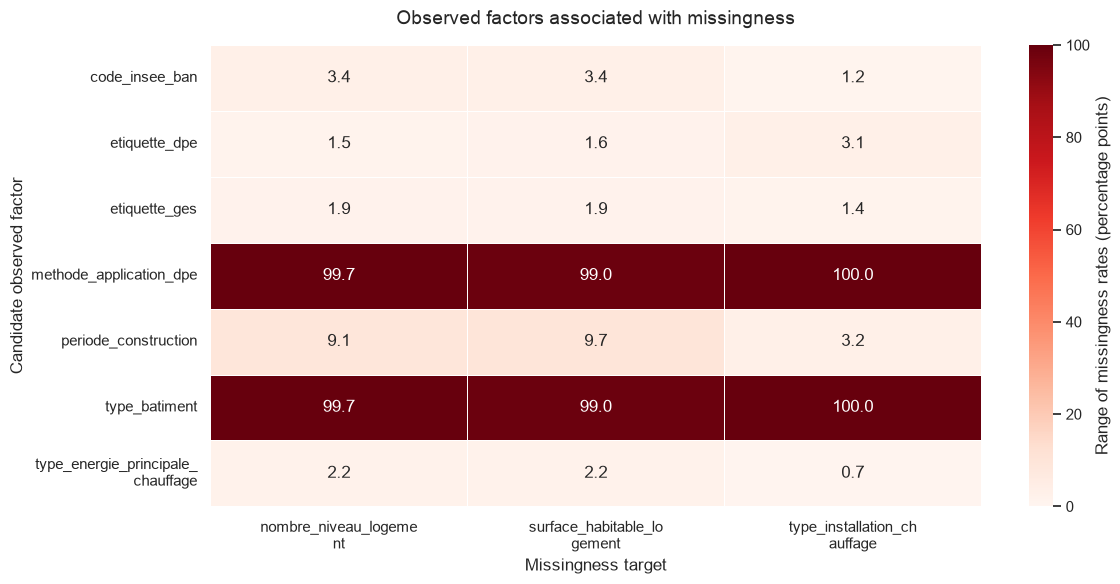

In [29]:
candidate_factors = []

for column in df.columns:
    if column in missing_columns:
        continue

    is_categorical = (
        is_object_dtype(df[column])
        or is_string_dtype(df[column])
        or is_categorical_dtype(df[column])
    )

    if is_categorical and df[column].nunique(dropna=True) <= 20:
        candidate_factors.append(column)

screening_results = []

for target in missing_columns:
    for factor in candidate_factors:
        temporary = pd.DataFrame({
            "is_missing": df[target].isna(),
            "factor_value": df[factor],
        })

        rates = (
            temporary
            .groupby("factor_value", dropna=False, observed=True)["is_missing"]
            .agg(["mean", "size"])
        )

        rates = rates[rates["size"] >= 20]

        if len(rates) >= 2:
            screening_results.append({
                "target": target,
                "factor": factor,
                "rate_range": rates["mean"].max() - rates["mean"].min(),
            })

screening = pd.DataFrame(screening_results)

screening_pivot = screening.pivot_table(
    index="target",
    columns="factor",
    values="rate_range",
    aggfunc="mean",
)

plot_data = screening_pivot.T * 100

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    plot_data,
    annot=True,
    fmt=".1f",
    cmap="Reds",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Range of missingness rates (percentage points)"
    },
    ax=ax,
)

ax.set_title(
    "Observed factors associated with missingness",
    fontsize=14,
    pad=15,
)

ax.set_xlabel("Missingness target")
ax.set_ylabel("Candidate observed factor")

ax.set_xticklabels(
    [
        textwrap.fill(str(label), width=20)
        for label in plot_data.columns
    ],
    rotation=0,
    ha="center",
)

ax.set_yticklabels(
    [
        textwrap.fill(str(label), width=24)
        for label in plot_data.index
    ],
    rotation=0,
    va="center",
)

plt.tight_layout()
plt.show()

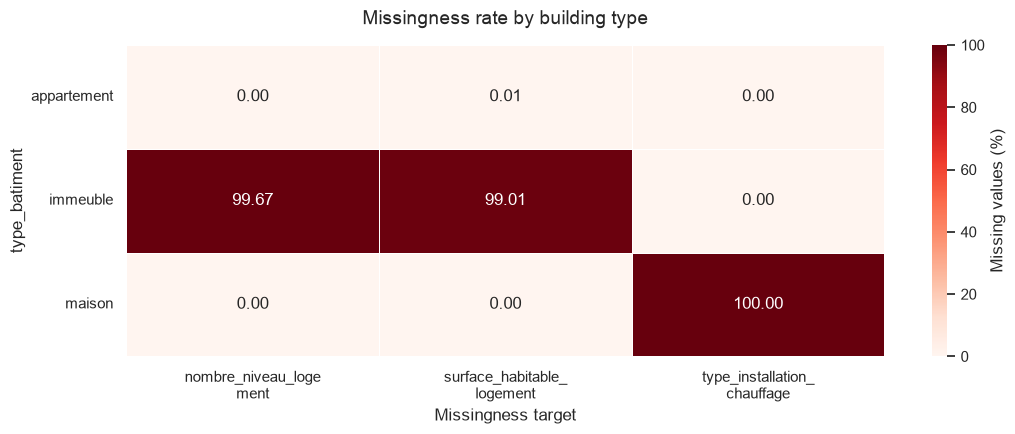

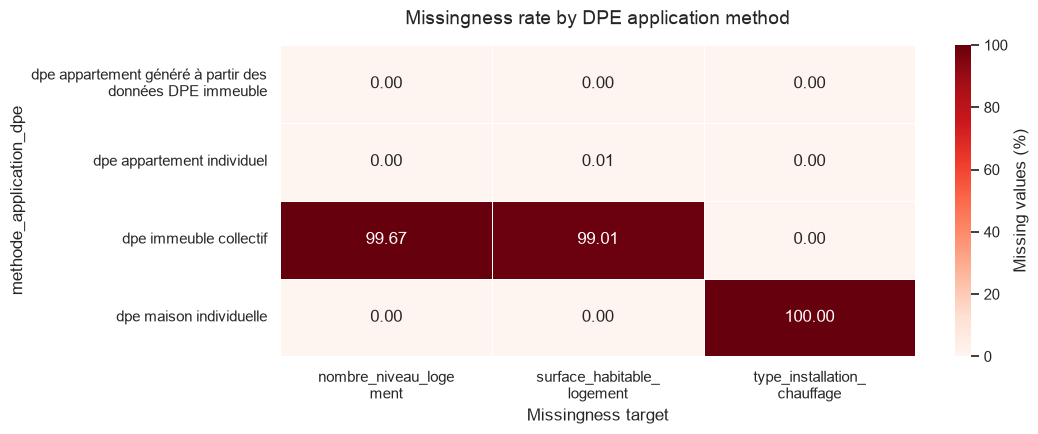

In [30]:

def plot_missingness_heatmap(group_column, title):
    rates = (
        df[missing_columns]
        .isna()
        .groupby(df[group_column], observed=True)
        .mean()
        .mul(100)
        .round(2)
    )

    fig, ax = plt.subplots(figsize=(11, 4.5))

    sns.heatmap(
        rates,
        annot=True,
        fmt=".2f",
        cmap="Reds",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            "label": "Missing values (%)"
        },
        ax=ax,
    )

    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel("Missingness target")
    ax.set_ylabel(group_column)

    ax.set_xticklabels(
        [
            textwrap.fill(str(label), width=18)
            for label in rates.columns
        ],
        rotation=0,
        ha="center",
    )

    ax.set_yticklabels(
        [
            textwrap.fill(str(label), width=35)
            for label in rates.index
        ],
        rotation=0,
        va="center",
    )

    plt.tight_layout()
    plt.show()


plot_missingness_heatmap(
    "type_batiment",
    "Missingness rate by building type",
)

plot_missingness_heatmap(
    "methode_application_dpe",
    "Missingness rate by DPE application method",
)

#### Missingness conclusion

Overall missingness is low. The missingness of the three main variables depends on the DPE record type:

- `nombre_niveau_logement` and `surface_habitable_logement` are mostly missing for `immeuble` records.
- `type_installation_chauffage` is missing for all `maison` records.

This suggests structural missingness, compatible with MAR, rather than MCAR.

We did not impute the missing values because the missingness appears structural and related to the type of DPE record. For collective-building records and houses, the missing fields may be non-applicable or not recorded in the same way. Replacing them with averages or arbitrary categories would invent information and could bias the analysis. The original missing values were therefore preserved as `NaN`.

The two isolated missing values in consumption and emissions were also kept.

In [31]:
decisions[:] = [
    decision
    for decision in decisions
    if decision["issue"] not in [
        "structural missingness",
        "isolated missing values",
    ]
]

for column in [
    "nombre_niveau_logement",
    "surface_habitable_logement",
    "type_installation_chauffage",
]:
    log(
        column=column,
        issue="structural missingness",
        n_rows=int(df[column].isna().sum()),
        decision="kept missing values; no imputation",
        why=(
            "Missingness depends on building type and DPE method. "
            "The pattern is compatible with structural missingness or MAR."
        ),
    )

for column in [
    "conso_5_usages_par_m2_ep",
    "emission_ges_5_usages_par_m2",
]:
    log(
        column=column,
        issue="isolated missing values",
        n_rows=int(df[column].isna().sum()),
        decision="kept missing values; no imputation",
        why=(
            "Only one value is missing, so the missingness mechanism "
            "cannot be meaningfully assessed."
        ),
    )

### 4.4 Outliers — triage, don't delete

In [32]:
column = "surface_habitable_logement"

values = df[column].dropna()
log_values = np.log1p(values)

q1 = log_values.quantile(0.25)
q3 = log_values.quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - IQR_K * iqr
upper_fence = q3 + IQR_K * iqr

outlier_mask = (
    (log_values < lower_fence)
    | (log_values > upper_fence)
)

outlier_indices = log_values.index[outlier_mask]

surface_outliers = (
    df.loc[outlier_indices]
    .sort_values(column, ascending=False)
)

print("Column:", column)
print("Number of flagged values:", len(surface_outliers))
print("Original-scale lower fence:", round(np.expm1(lower_fence), 2))
print("Original-scale upper fence:", round(np.expm1(upper_fence), 2))

display(
    surface_outliers[
        [
            "numero_dpe",
            "surface_habitable_logement",
            "type_batiment",
            "methode_application_dpe",
            "etiquette_dpe",
            "adresse_ban",
        ]
    ].head(10)
)

Column: surface_habitable_logement
Number of flagged values: 121
Original-scale lower fence: 8.18
Original-scale upper fence: 194.61


,numero_dpe,surface_habitable_logement,type_batiment,methode_application_dpe,etiquette_dpe,adresse_ban
6493,2175E0686839U,1876.0,immeuble,dpe immeuble collectif,D,61 Rue de Lourmel 75015 Paris
6446,2175E0687695S,1151.0,immeuble,dpe immeuble collectif,C,126 Rue Saint-Charles 75015 Paris
4322,2675E0067774U,422.4,appartement,dpe appartement individuel,D,10 Avenue Elisée Reclus 75007 Paris
8188,2675E0174841T,373.6,appartement,dpe appartement individuel,D,11 Quai Anatole France 75007 Paris
7716,2675E0190129T,368.6,appartement,dpe appartement individuel,E,181 Avenue du Maine 75014 Paris
857,2675E0023603X,363.7,appartement,dpe appartement individuel,D,32 Avenue Georges Mandel 75016 Paris
7521,2675E0194213V,362.0,appartement,dpe appartement individuel,D,6 Rue de Tournon 75006 Paris
6981,2675E0190648S,342.2,appartement,dpe appartement individuel,F,127 Avenue de Malakoff 75016 Paris
3267,2675E0006587L,342.0,appartement,dpe appartement individuel,E,22 Avenue de Friedland 75008 Paris
2780,2675E0047628Y,340.4,appartement,dpe appartement individuel,D,32 Avenue Foch 75016 Paris


In [33]:
surface_outliers = surface_outliers.copy()

surface_outliers["outlier_direction"] = np.select(
    [
        surface_outliers["surface_habitable_logement"] < lower_fence,
        surface_outliers["surface_habitable_logement"] > upper_fence,
    ],
    [
        "below lower threshold",
        "above upper threshold",
    ],
    default="check",
)

outlier_by_type = (
    surface_outliers
    .groupby(
        ["outlier_direction", "type_batiment"],
        dropna=False,
    )
    .agg(
        n_outliers=("surface_habitable_logement", "size"),
        minimum_surface=("surface_habitable_logement", "min"),
        maximum_surface=("surface_habitable_logement", "max"),
    )
    .sort_values(
        ["outlier_direction", "n_outliers"],
        ascending=[True, False],
    )
)

outlier_by_type

n_outliers  minimum_surface  \
outlier_direction     type_batiment                                
above upper threshold appartement           106              5.6   
                      maison                  8            195.6   
                      immeuble                2           1151.0   
check                 appartement             5              3.4   

                                     maximum_surface  
outlier_direction     type_batiment                   
above upper threshold appartement              422.4  
                      maison                   323.7  
                      immeuble                1876.0  
check                 appartement                4.8

#### Outliers conclusion

The log-IQR method flagged 121 surface values as statistical outliers. After examining their direction and building type, the values appeared contextually plausible: small values were associated with apartments, large values were associated with apartments, houses, and collective buildings. No clear data-entry errors were identified. All values were therefore retained.

In [34]:
df["surface_outlier_flag"] = df.index.isin(surface_outliers.index)

print(
    "Flagged surface outliers:",
    int(df["surface_outlier_flag"].sum())
)

Flagged surface outliers: 121


In [35]:
log(
    column="surface_habitable_logement",
    issue="IQR outliers",
    n_rows=121,
    decision="kept all rows; flagged for review",
    why=(
        "The values were statistically unusual but plausible for the observed "
        "apartments, houses, and collective buildings. No confirmed errors were found."
    ),
)

In [36]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,multiple,column selection,10000,kept 17 columns,Kept the nine fields suggested by the project ...
1,all,exact duplicates,0,kept all rows,No complete duplicate rows were found in the s...
2,selected fields except numero_dpe,candidate duplicates,1856,flagged and retained,Rows match exactly across the selected descrip...
3,surface_habitable_logement,impossible values,0,kept all rows,The minimum values were all physically or logi...
4,conso_5_usages_par_m2_ep,impossible values,0,kept all rows,The minimum values were all physically or logi...
5,emission_ges_5_usages_par_m2,impossible values,0,kept all rows,The minimum values were all physically or logi...
6,nombre_niveau_logement,impossible values,0,kept all rows,The minimum values were all physically or logi...
7,nombre_niveau_logement,structural missingness,301,kept missing values; no imputation,Missingness depends on building type and DPE m...
8,surface_habitable_logement,structural missingness,300,kept missing values; no imputation,Missingness depends on building type and DPE m...
9,type_installation_chauffage,structural missingness,46,kept missing values; no imputation,Missingness depends on building type and DPE m...


---
## 5 · Exploration :- every figure gets a caption and a *so what*

In [37]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.loc[:, KEEP].copy()

print("Clean data shape:", clean.shape)
print("Number of clean columns:", len(clean.columns))

Clean data shape: (10000, 17)
Number of clean columns: 17


### 5.1 Univariate

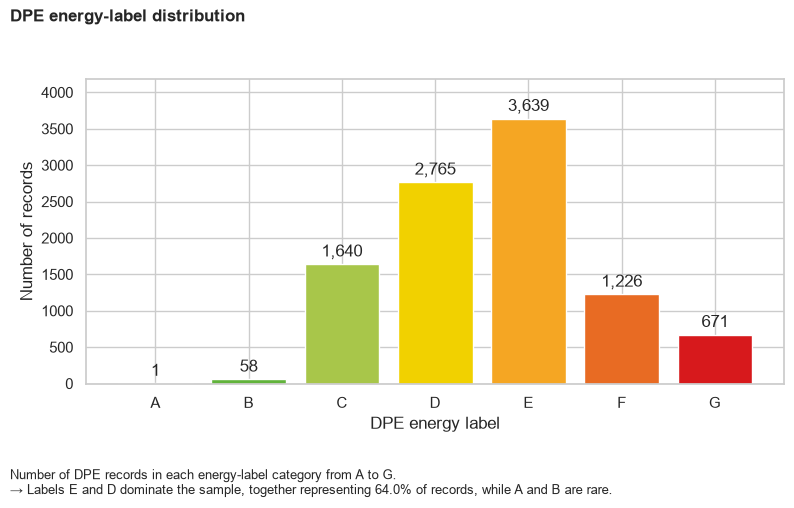

In [38]:
labels = list("ABCDEFG")

label_counts = (
    clean["etiquette_dpe"]
    .value_counts()
    .reindex(labels, fill_value=0)
)

label_percent = label_counts / len(clean) * 100

colors = {
    "A": "#008C45",
    "B": "#61B33B",
    "C": "#A8C64A",
    "D": "#F1D100",
    "E": "#F5A623",
    "F": "#E86B23",
    "G": "#D7191C",
}

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    label_counts.index,
    label_counts.values,
    color=[colors[label] for label in label_counts.index],
)

ax.bar_label(bars, labels=[f"{value:,}" for value in label_counts.values], padding=3)

ax.set_xlabel("DPE energy label")
ax.set_ylabel("Number of records")
ax.set_ylim(0, label_counts.max() * 1.15)

top_two = label_counts.sort_values(ascending=False).head(2)
top_two_share = top_two.sum() / len(clean) * 100

show(
    fig,
    "DPE energy-label distribution",
    "Number of DPE records in each energy-label category from A to G.",
    (
        f"Labels {top_two.index[0]} and {top_two.index[1]} dominate the sample, "
        f"together representing {top_two_share:.1f}% of records, while A and B are rare."
    ),
    "5_1_dpe_label_distribution",
)

### 5.2 Bivariate

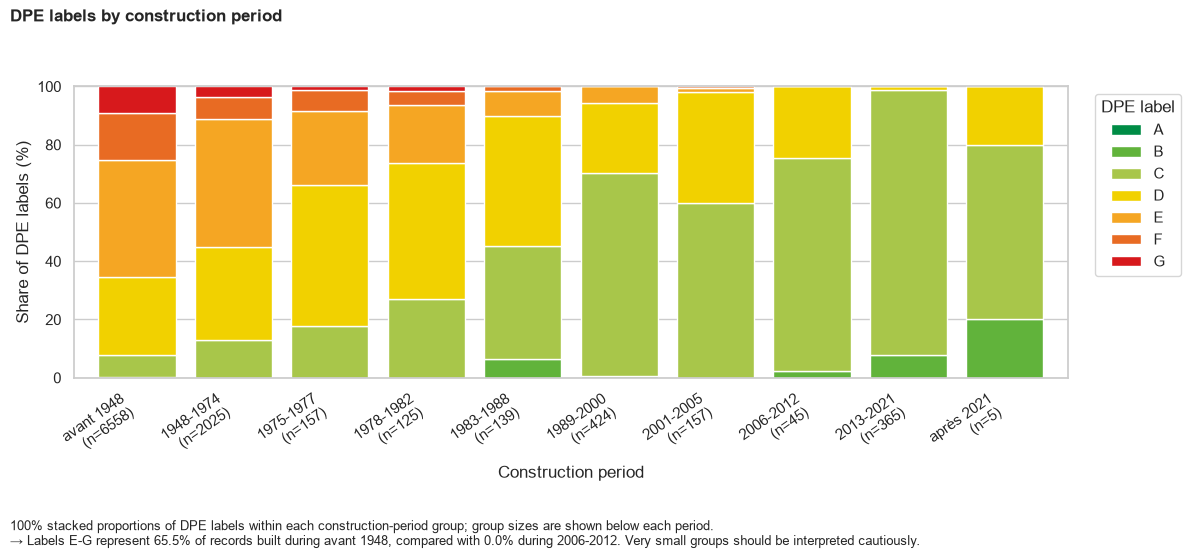

In [39]:
period_order = [
    "avant 1948",
    "1948-1974",
    "1975-1977",
    "1978-1982",
    "1983-1988",
    "1989-2000",
    "2001-2005",
    "2006-2012",
    "2013-2021",
    "après 2021",
]

labels = list("ABCDEFG")

label_by_period = pd.crosstab(
    clean["periode_construction"],
    clean["etiquette_dpe"],
    normalize="index",
).mul(100)

label_by_period = (
    label_by_period
    .reindex(index=period_order, columns=labels, fill_value=0)
)

period_counts = (
    clean["periode_construction"]
    .value_counts()
    .reindex(period_order)
    .fillna(0)
    .astype(int)
)

colors = {
    "A": "#008C45",
    "B": "#61B33B",
    "C": "#A8C64A",
    "D": "#F1D100",
    "E": "#F5A623",
    "F": "#E86B23",
    "G": "#D7191C",
}

fig, ax = plt.subplots(figsize=(12, 5))

label_by_period.plot(
    kind="bar",
    stacked=True,
    color=[colors[label] for label in labels],
    ax=ax,
    width=0.8,
)

ax.set_xticklabels(
    [
        f"{period}\n(n={period_counts.loc[period]})"
        for period in period_order
    ],
    rotation=35,
    ha="right",
)

ax.set_xlabel("Construction period")
ax.set_ylabel("Share of DPE labels (%)")
ax.set_ylim(0, 100)
ax.legend(
    title="DPE label",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

poor_share = label_by_period[["E", "F", "G"]].sum(axis=1)
largest_poor_share_period = poor_share.idxmax()
smallest_poor_share_period = poor_share.idxmin()

show(
    fig,
    "DPE labels by construction period",
    "100% stacked proportions of DPE labels within each construction-period group; group sizes are shown below each period.",
    (
        f"Labels E-G represent {poor_share.loc[largest_poor_share_period]:.1f}% "
        f"of records built during {largest_poor_share_period}, compared with "
        f"{poor_share.loc[smallest_poor_share_period]:.1f}% during "
        f"{smallest_poor_share_period}. Very small groups should be interpreted cautiously."
    ),
    "5_2_labels_by_construction_period",
)

### 5.3 Multivariate

In [40]:
analysis = clean.dropna(
    subset=[
        "surface_habitable_logement",
        "etiquette_dpe",
        "type_batiment",
    ]
)

labels = list("ABCDEFG")
building_order = ["appartement", "immeuble", "maison"]

median_surface = (
    analysis
    .pivot_table(
        index="type_batiment",
        columns="etiquette_dpe",
        values="surface_habitable_logement",
        aggfunc="median",
    )
    .reindex(index=building_order, columns=labels)
)

group_counts = (
    analysis
    .pivot_table(
        index="type_batiment",
        columns="etiquette_dpe",
        values="surface_habitable_logement",
        aggfunc="count",
    )
    .reindex(index=building_order, columns=labels)
)

annotations = median_surface.copy().astype(object)

for row in median_surface.index:
    for column in median_surface.columns:
        median_value = median_surface.loc[row, column]
        count_value = group_counts.loc[row, column]

        if pd.isna(median_value):
            annotations.loc[row, column] = ""
        else:
            annotations.loc[row, column] = (
                f"{median_value:.1f}\n(n={int(count_value)})"
            )

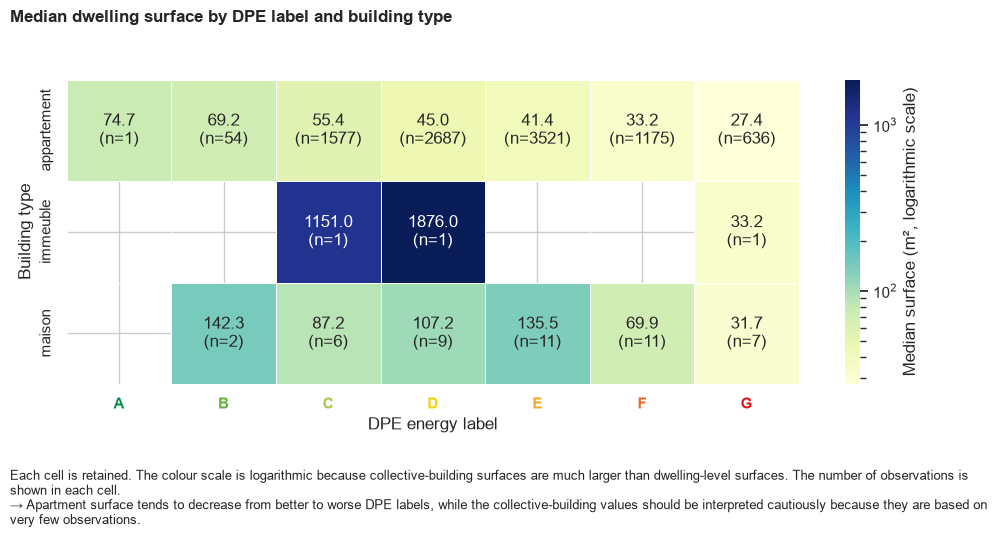

In [41]:

positive_values = median_surface.to_numpy()
positive_values = positive_values[positive_values > 0]

fig, ax = plt.subplots(figsize=(10, 4.5))

sns.heatmap(
    median_surface,
    annot=annotations,
    fmt="",
    cmap="YlGnBu",
    norm=LogNorm(
        vmin=positive_values.min(),
        vmax=positive_values.max(),
    ),
    linewidths=0.5,
    linecolor="white",
    cbar_kws={
        "label": "Median surface (m², logarithmic scale)"
    },
    ax=ax,
)

ax.set_xlabel("DPE energy label")
ax.set_ylabel("Building type")

dpe_colors = {
    "A": "#008C45",
    "B": "#61B33B",
    "C": "#A8C64A",
    "D": "#F1D100",
    "E": "#F5A623",
    "F": "#E86B23",
    "G": "#D7191C",
}

for tick, label in zip(ax.get_xticklabels(), labels):
    tick.set_color(dpe_colors[label])
    tick.set_fontweight("bold")

show(
    fig,
    "Median dwelling surface by DPE label and building type",
    "Each cell is retained. The colour scale is logarithmic because collective-building surfaces are much larger than dwelling-level surfaces. The number of observations is shown in each cell.",
    "Apartment surface tends to decrease from better to worse DPE labels, while the collective-building values should be interpreted cautiously because they are based on very few observations.",
    "5_3_surface_by_label_and_building_type",
)

---
## 6 · Findings, what cannot be trusted, next steps

*TODO*

**Three findings** — each with the figure it comes from and what it means for modelling.
1. **DPE labels are concentrated in categories D and E.**  
   Figure `5_1_dpe_label_distribution` shows that labels D and E represent approximately 64% of the sample, while A and B are rare. This class imbalance should be considered in modelling, because overall accuracy could hide poor performance for rare labels.
2. **Older buildings are associated with poorer DPE labels.**  
   Figure `5_2_labels_by_construction_period` shows a clear shift in the DPE-label distribution across construction periods. Labels E to G represent 65.5% of records built before 1948, compared with 0.0% of records built between 2006 and 2012. Newer buildings are more frequently classified as B or C. This suggests that construction period is an important explanatory variable for modelling DPE labels, although the relationship is observational and may also reflect renovation, building type, heating system, or surface.
3. **Among apartments, median surface tends to decrease as the DPE label worsens.**  
   Figure `5_3_surface_by_label_and_building_type` shows that median apartment surface decreases from approximately 69.2 m² for label B to 27.4 m² for label G. This suggests that surface and building type may be useful explanatory variables, but the relationship should not be interpreted as causal. Cells with very few observations, especially collective-building records, are unreliable.

**What cannot be trusted**

- `surface_habitable_logement` for `type_batiment = "immeuble"` cannot be interpreted confidently because very few non-missing values are available. The corresponding medians are based on only one or a few records.

- DPE-label proportions for very small construction-period groups, especially `après 2021` with only 5 records, cannot be generalised. These percentages are unstable and should only be treated as descriptive.

- `type_installation_chauffage` for `type_batiment = "maison"` cannot be analysed because all values are missing in this group. Missing does not mean that the houses have no heating installation.

- The records cannot be assumed to represent 10,000 independent and unique dwellings. No complete duplicate rows were found, but 1,856 rows matched across the selected descriptive fields while having different `numero_dpe` values. These records were retained because they may represent distinct apartments with identical characteristics or repeated/generated DPE records. As a result, some addresses or buildings may be overrepresented, and the statistical results should be interpreted as record-level associations rather than conclusions about unique dwellings.

- The results should not be treated as representative of all Parisian DPE records because the analysis uses a capped sample of 10,000 records from a much larger filtered population.

**Five testable hypotheses** — variable, direction, population, test.

- **H1:** `periode_construction`; older buildings are expected to have a higher proportion of poor DPE labels, especially E to G; population: all Paris DPE records in the 10,000-row sample; test: chi-square test of independence and comparison of E-G proportions by construction period.

- **H2:** `surface_habitable_logement`; among apartments, smaller surfaces are expected to be associated with worse DPE labels; population: apartment records with non-missing surface and DPE label; test: Spearman correlation using an ordinal DPE score comparing surface across labels.

- **H3:** `type_energie_principale_chauffage`; fossil-energy systems, especially gas and fioul, are expected to be associated with a higher proportion of E-G labels than electricity or urban heating networks; population: records with non-missing heating-energy type and DPE label; test: chi-square test or logistic regression for the outcome E-G versus A-D.

- **H4:** `etiquette_ges`; worse GES labels are expected to be associated with worse DPE energy labels; population: all records with both DPE and GES labels; test: chi-square test of independence and Cramér’s V.

- **H5:** `type_batiment`; DPE-label distributions are expected to differ between apartments, houses, and collective buildings; population: records with a valid building type and DPE label; test: chi-square test or multinomial logistic regression.

### Final contract & fingerprint
*TODO*: write `clean_schema` for the data a modeller receives (it may differ from the raw schema). Then **Restart & Run All twice**: the fingerprint must be identical.

In [42]:
clean_schema = schema

clean_schema.validate(clean, lazy=True)

print("✅ clean data passes the contract")

clean.to_parquet(
    DATA / "processed" / "clean.parquet",
    index=False,
)

fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(
        clean.astype(str),
        index=False,
    ).values.tobytes()
).hexdigest()[:12]

print("rows:", len(clean))
print("fingerprint:", fingerprint)

✅ clean data passes the contract
rows: 10000
fingerprint: 82c5585f6f33


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected — record the collection date in Section 1 and in the README, and commit the raw Parquet if it is small enough.